$$
T(x_0) = \sqrt{8m} \;\int_{0}^{x_0} \frac{dx}{\sqrt{V(x_0) - V(x)}}.
$$

### Richeste
Partendo dalla formula per il periodo $T$ appena ricavata, produrre uno script python che:
1. calcoli il periodo in funzione del punto di partenza $x_0$ (utilizzando `scipy.integrate.simpson`); 
2. produca un grafico di $T$ in funzione di $x_0$;
3. ripetere l'analisi precedente per un'energia potenziale del tipo $V_a(x) = k x^2$ e confrontare i risultati
4. provare formule alternative per $V(x)$ (rispettando la condizione di simmetria rispetto all'origine) e confrontare i risultati.
- Esempi: $V(x) = k x^4$,  $V(x) = k|x|^{3/2}$;
5. utilizzare il modulo `argparse` per permettere all'utente di scegliere le opzioni sul potenziale da visualizzare.

In [ ]:
def calcola_T(x_0, V, m=1.0, n=10001):
    """Calcola T(x_0) = sqrt(8m) * integral_0^x0 dx/sqrt(V(x0)-V(x))."""
    if x_0 <= 0 or m <= 0:
        raise ValueError("x_0 e m devono essere positivi.")
    if n < 3:
        raise ValueError("n deve essere almeno 3.")
    if n % 2 == 0:
        n += 1  # numero dispari di punti per la regola di Simpson

    u = np.linspace(0.0, 1.0, n)
    x = x_0 * (1.0 - u**2)
    delta_v = V(x_0) - V(x)

    if np.any(delta_v[1:] <= 0):
        raise ValueError("V(x_0) - V(x) deve essere positivo per 0 <= x < x_0.")

    integrando = np.empty_like(u)
    integrando[1:] = 2.0 * x_0 * u[1:] / np.sqrt(delta_v[1:])
    integrando[0] = integrando[1]  # limite finito in u = 0

    return np.sqrt(8.0 * m) * integrate.simpson(integrando, x=u)

In [ ]:
def calcola_T(x_0):
    return integrate.simpson()
    

In [ ]:
from scipy import integrate
import argparse as arg
import numpy as np

def parse_arguments():
    
    parser = arg.ArgumentParser(description='Esempio utilizzo argarse.',usage='python3 argparse_example.py  --opzione')
    parser.add_argument('-m', default=1, help='inserisce il valore della massa del corpo, dafault =1')
    parser.add_argument('-p1',    action='store_true', default=False, help='visualizza risoluzione per il potenziale 1')
    parser.add_argument('-p2',    action='store_true', default=False, help='visualizza risoluzione per il potenziale 2')
    parser.add_argument('-p3',    action='store_true', default=False, help='visualizza risoluzione per il potenziale 3')
    parser.add_argument('-p4',    action='store_true', default=False, help='visualizza risoluzione per il potenziale 4')
    return  parser.parse_args()


In [2]:
import pandas as pd
import matplotlib.pyplot as plt
df=pd.read_csv("oscilloscope.csv")
df

,time,signal1,signal2
0,0,0.63,1.18
1,1,2.75,-1.78
2,2,1.81,-0.07
3,3,2.22,-3.70
4,4,0.35,2.81
...,...,...,...
49911,49911,-0.98,1.59
49912,49912,1.24,-4.27
49913,49913,-0.83,2.01
49914,49914,-1.16,3.63


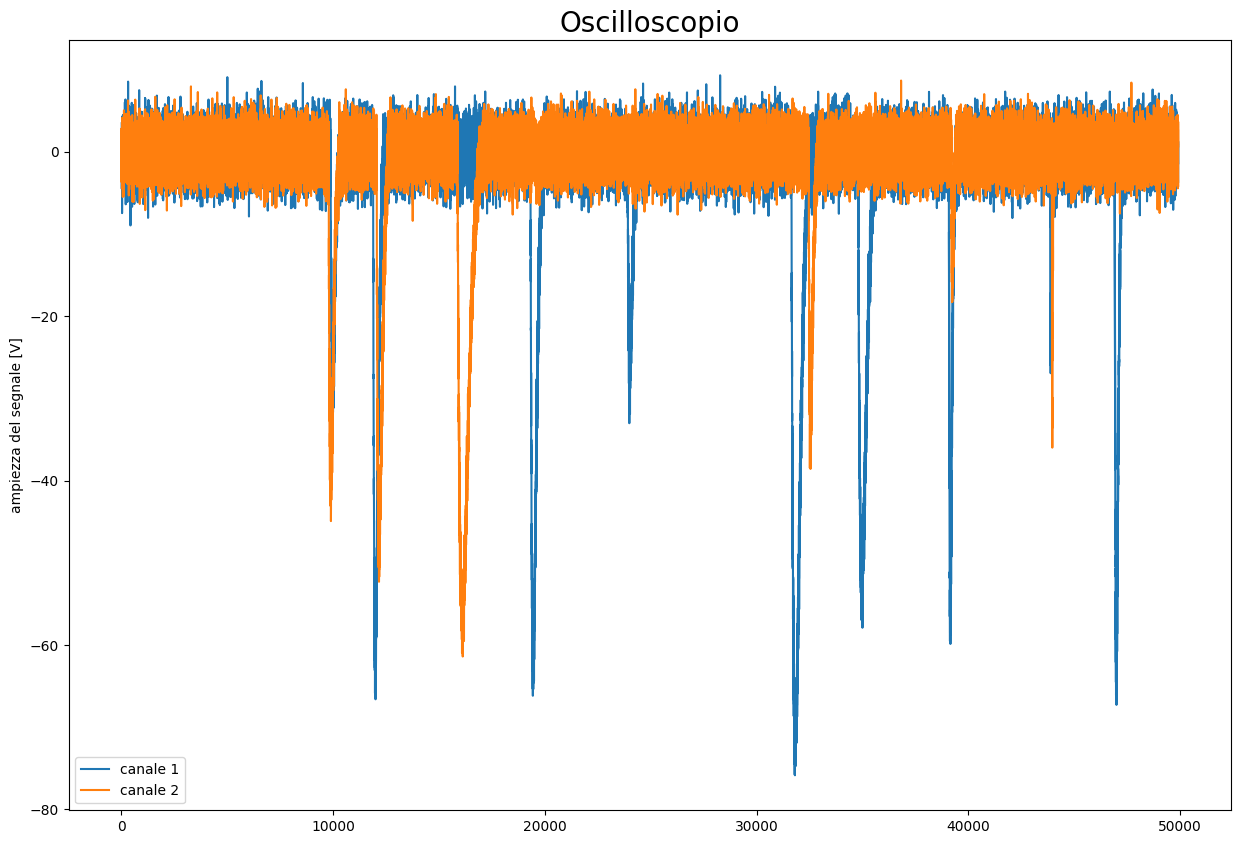

In [11]:
plt.figure(figsize=(15,10))
plt.plot(df['time'], df['signal1'], label='canale 1')
plt.plot(df['time'], df['signal2'], label='canale 2')
plt.ylabel('ampiezza del segnale [V]')
plt.title("Oscilloscopio", fontsize=20)
plt.legend()
plt.savefig("ocsilloscopio.png")
plt.show()


$$
f'(i) = \frac{ f(i+1) - f(i-1)}{ x(i+1) - x(i-1) }.
$$

In [3]:
def der_centrale(dati,step:int): 
  df_der = pd.DataFrame({
                        'time': [],
                        'der_1': [],
                        'der_2': []})
  df_der['time']=[]
  df=dati
  for l in range(1, int(len(dati['time']) / step) - 1):
      i = l * step
      d=int(step/2)
      df_der.loc[l, 'time'] = df['time'][i]
      df_der.loc[l, 'der_1'] = (df['signal1'][i + d] - df['signal1'][i - d]) / (df['time'][i + d] - df['time'][i - d])
      df_der.loc[l, 'der_2'] = (df['signal2'][i + d] - df['signal2'][i - d]) / (df['time'][i + d] - df['time'][i - d])

  plt.figure(figsize=(15, 10))
  plt.plot(df_der['time'], df_der['der_1'], label='canale 1')
  plt.plot(df_der['time'], df_der['der_2'], label='canale 2')
  plt.xlabel('tempo [s]')
  plt.ylabel('derivata segnale [V/s]')
  plt.title(f"derivate oscilloscopio n={step}", fontsize=20)
  plt.legend()
  plt.savefig(f"ocsilloscopio_n{step}.png")
  plt.show()
  return df_der

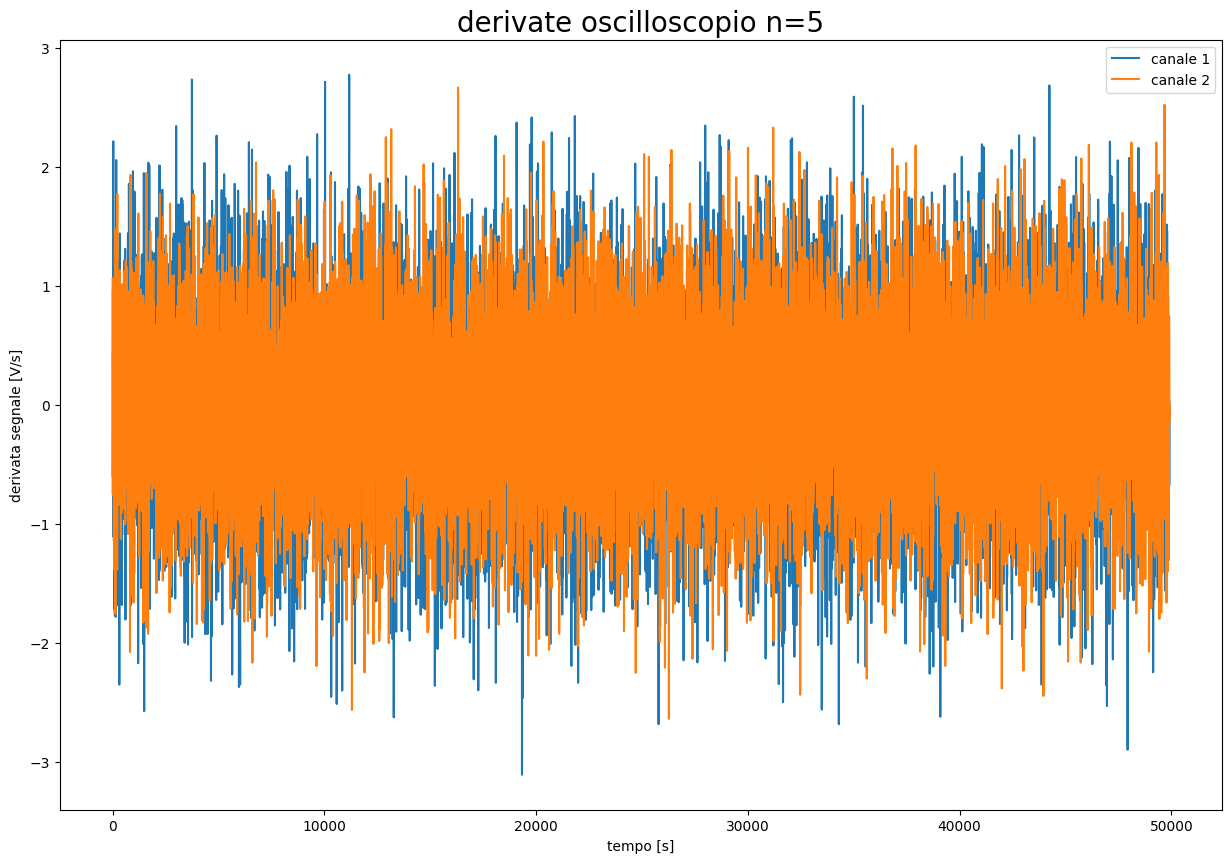

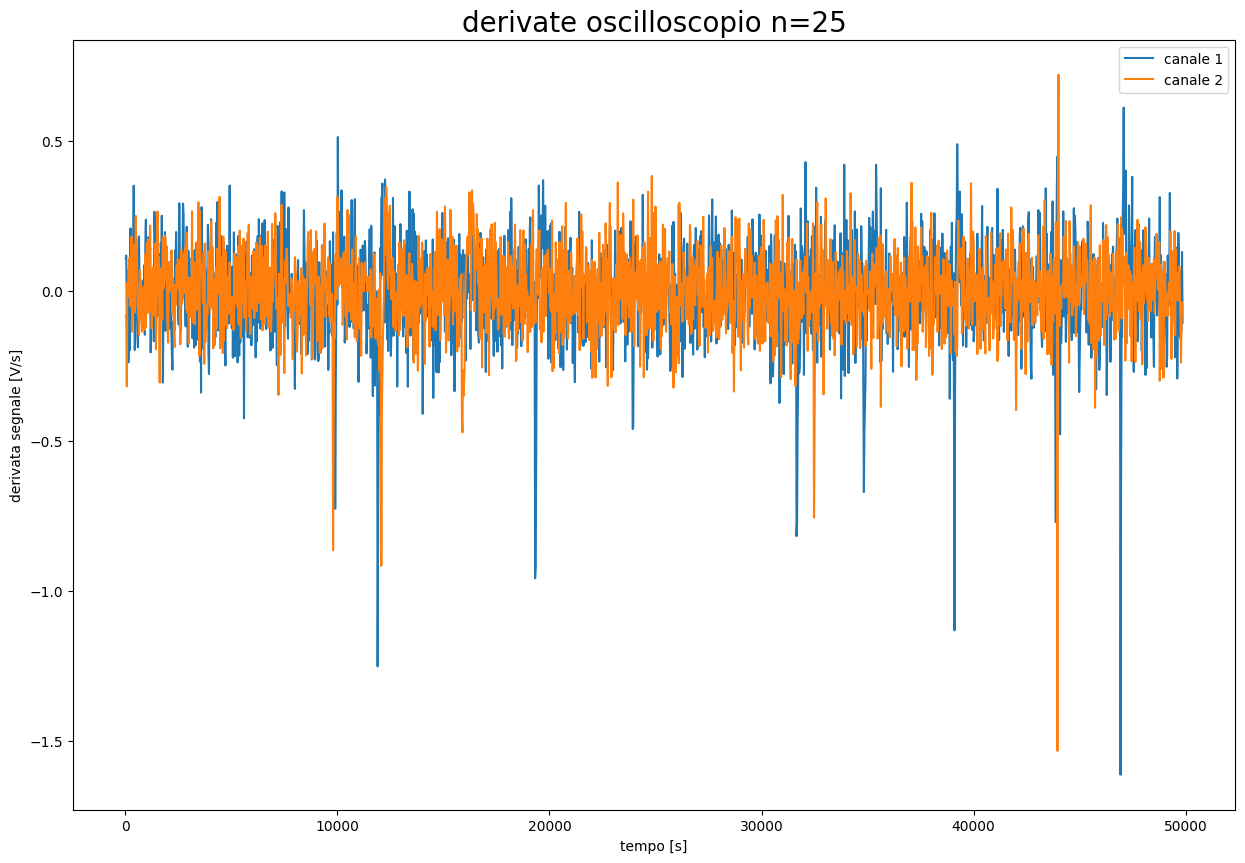

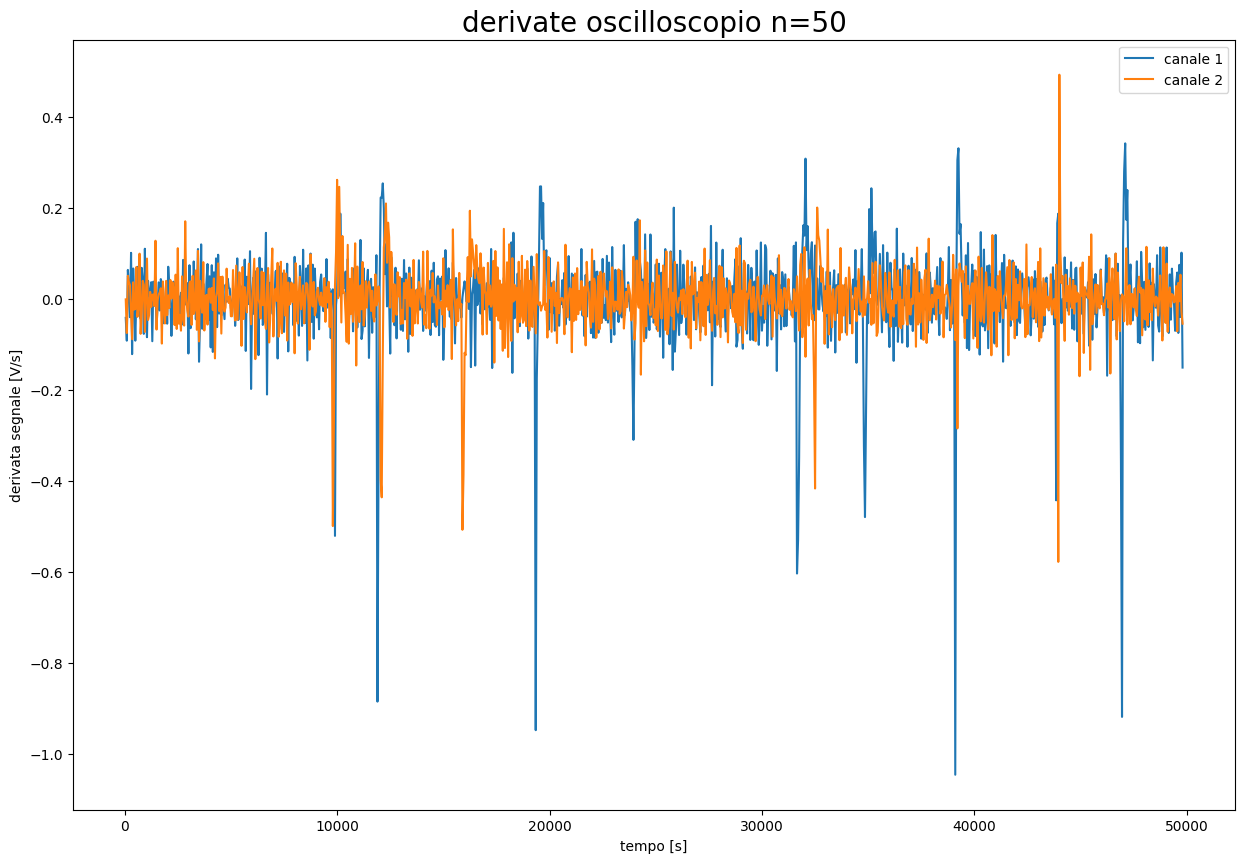

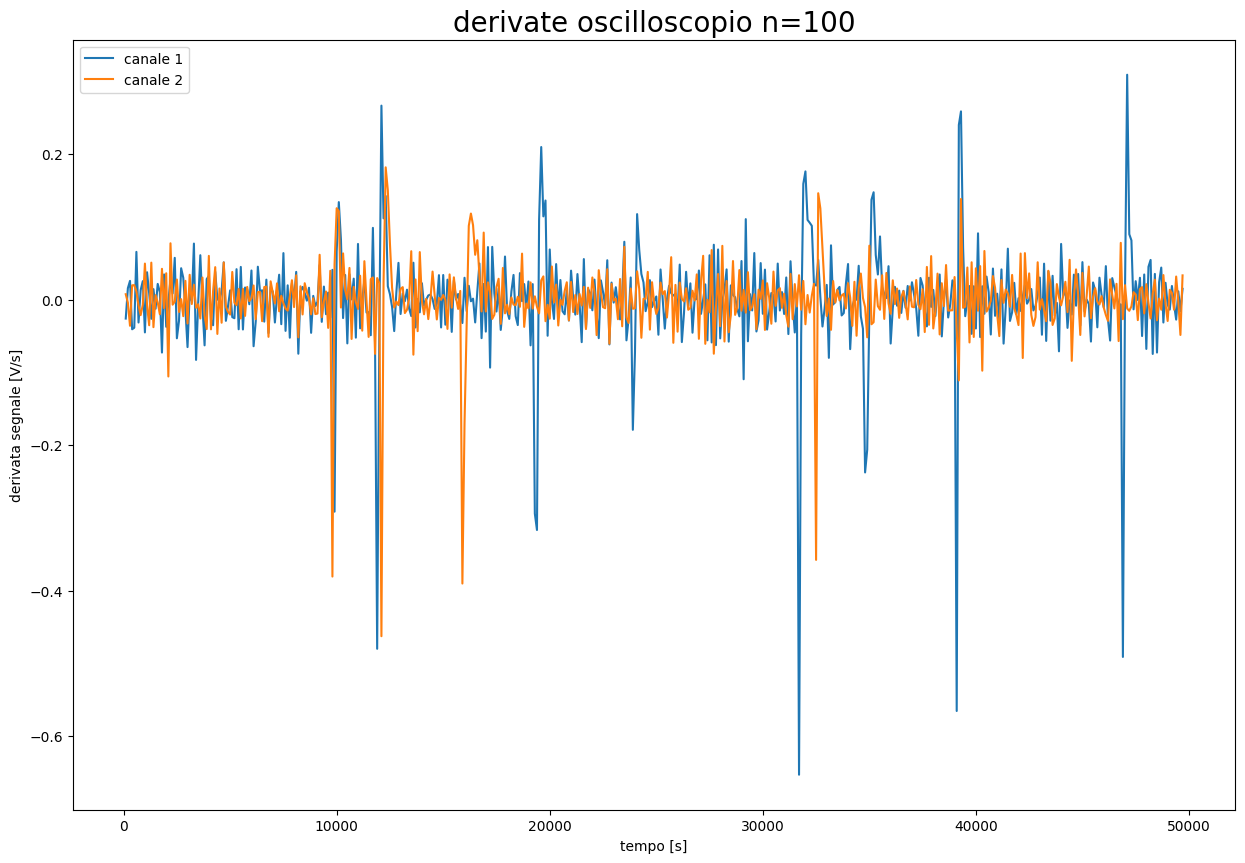

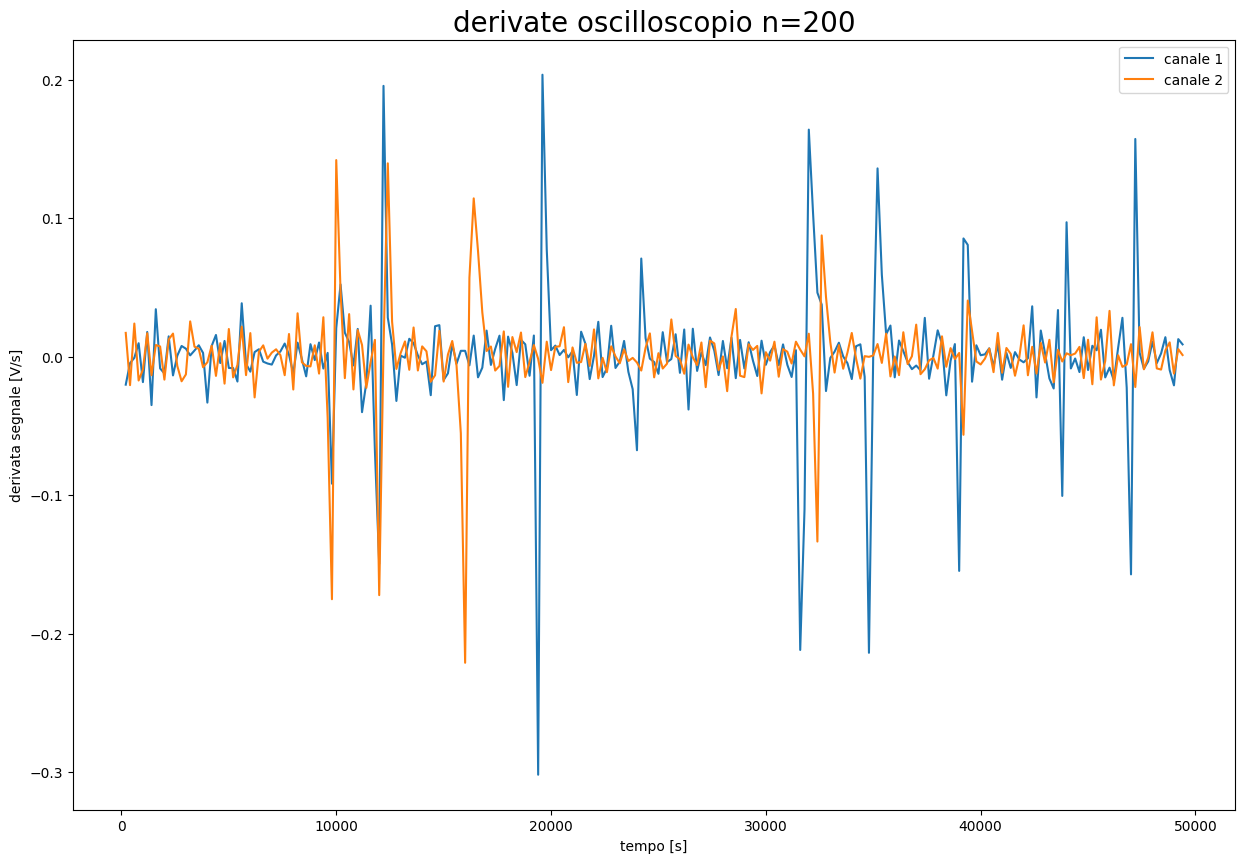

In [4]:
steps=[5,25,50,100,200]
data=[]
for s in steps:
    la=der_centrale(df,s)
    data.append(la)

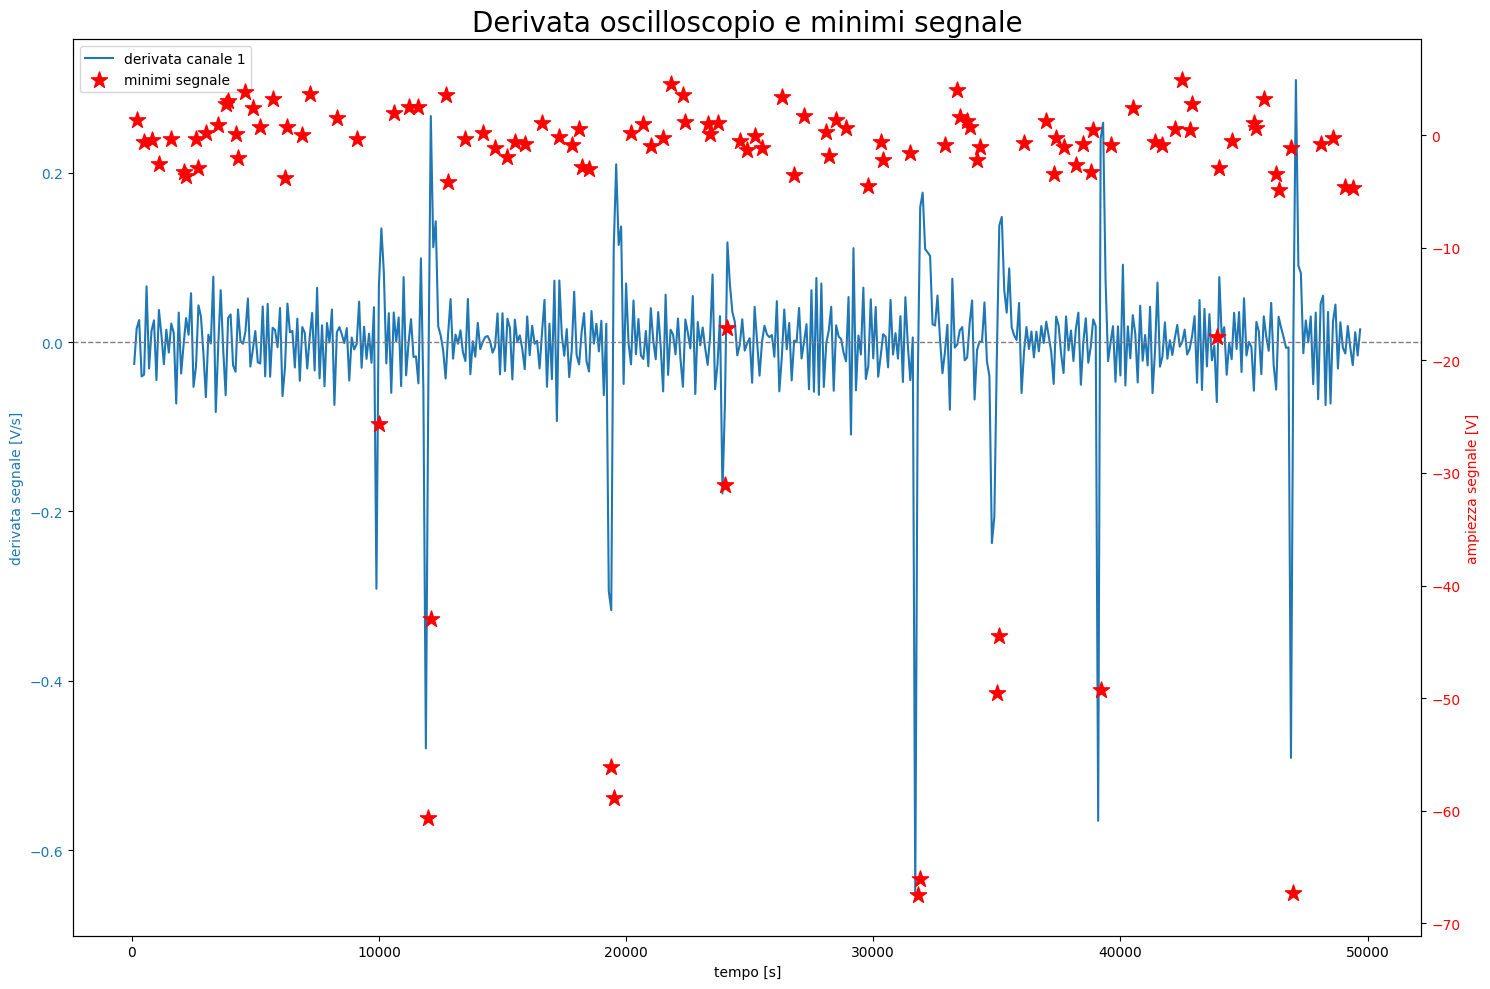

In [ ]:
dati_min = data[3]  # corrisponde a step = 100
der1 = dati_min['der_1'].reset_index(drop=True)
tempi_der = dati_min['time'].reset_index(drop=True)

mins_idx = []
for i in range(1, len(der1) - 1):
    # Attraversamento dello zero da negativo a positivo -> minimo locale del segnale
    if der1.iloc[i - 1] < 0 and der1.iloc[i + 1] > 0:
        mins_idx.append(i)

t_minimi = tempi_der.iloc[mins_idx]
idx_df = df['time'].searchsorted(t_minimi).clip(0, len(df) - 1)

fig, ax1 = plt.subplots(figsize=(15, 10))

# Asse y sinistro: derivata [V/s]
line1, = ax1.plot(tempi_der, der1, color='tab:blue', label='derivata canale 1')
ax1.axhline(0, color='gray', linestyle='--', linewidth=1)
ax1.set_xlabel('tempo [s]')
ax1.set_ylabel('derivata segnale [V/s]', color='tab:blue')
ax1.tick_params(axis='y', labelcolor='tab:blue')

# Asse y destro (secondario): minimi di signal1 [V] tramite scatter
ax2 = ax1.twinx()
scatter2 = ax2.scatter(df['time'].iloc[idx_df], df['signal1'].iloc[idx_df],
            marker="*", color='red', s=150, label='minimi segnale')
ax2.set_ylabel('ampiezza segnale [V]', color='red')
ax2.tick_params(axis='y', labelcolor='red')

plt.title("Derivata oscilloscopio e minimi segnale", fontsize=20)

# Legenda combinata di entrambi gli assi
handles = [line1, scatter2]
labels = [h.get_label() for h in handles]
ax1.legend(handles, labels, loc='best')

plt.tight_layout()
plt.savefig('min1.png')
plt.show()

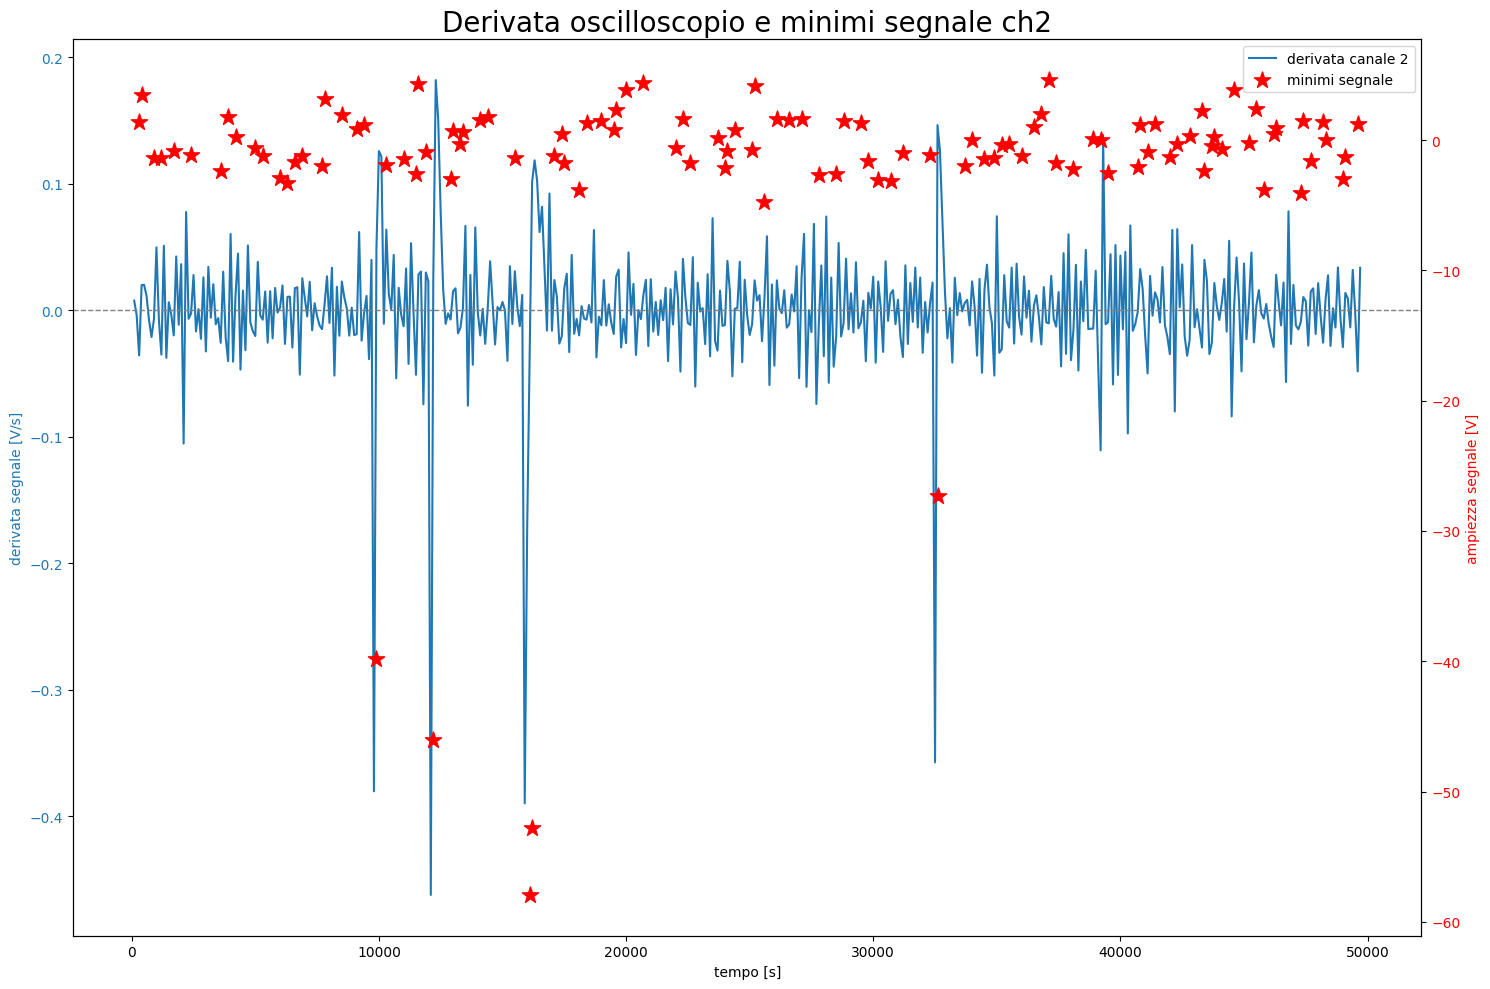

In [33]:
dati_min = data[3]  # corrisponde a step = 100
der1 = dati_min['der_2'].reset_index(drop=True)
tempi_der = dati_min['time'].reset_index(drop=True)

mins_idx = []
for i in range(1, len(der1) - 1):
    # Attraversamento dello zero da negativo a positivo -> minimo locale del segnale
    if der1.iloc[i - 1] < 0 and der1.iloc[i + 1] > 0:
        mins_idx.append(i)

t_minimi = tempi_der.iloc[mins_idx]
idx_df = df['time'].searchsorted(t_minimi).clip(0, len(df) - 1)

fig, ax1 = plt.subplots(figsize=(15, 10))

# Asse y sinistro: derivata [V/s]
line1, = ax1.plot(tempi_der, der1, color='tab:blue', label='derivata canale 2')
ax1.axhline(0, color='gray', linestyle='--', linewidth=1)
ax1.set_xlabel('tempo [s]')
ax1.set_ylabel('derivata segnale [V/s]', color='tab:blue')
ax1.tick_params(axis='y', labelcolor='tab:blue')

# Asse y destro (secondario): minimi di signal1 [V] tramite scatter
ax2 = ax1.twinx()
scatter2 = ax2.scatter(df['time'].iloc[idx_df], df['signal2'].iloc[idx_df],
            marker="*", color='red', s=150, label='minimi segnale')
ax2.set_ylabel('ampiezza segnale [V]', color='red')
ax2.tick_params(axis='y', labelcolor='red')

plt.title("Derivata oscilloscopio e minimi segnale ch2", fontsize=20)

# Legenda combinata di entrambi gli assi
handles = [line1, scatter2]
labels = [h.get_label() for h in handles]
ax1.legend(handles, labels, loc='best')

plt.tight_layout()
plt.savefig('min2.png')
plt.show()

ValueError: x and y must be the same size

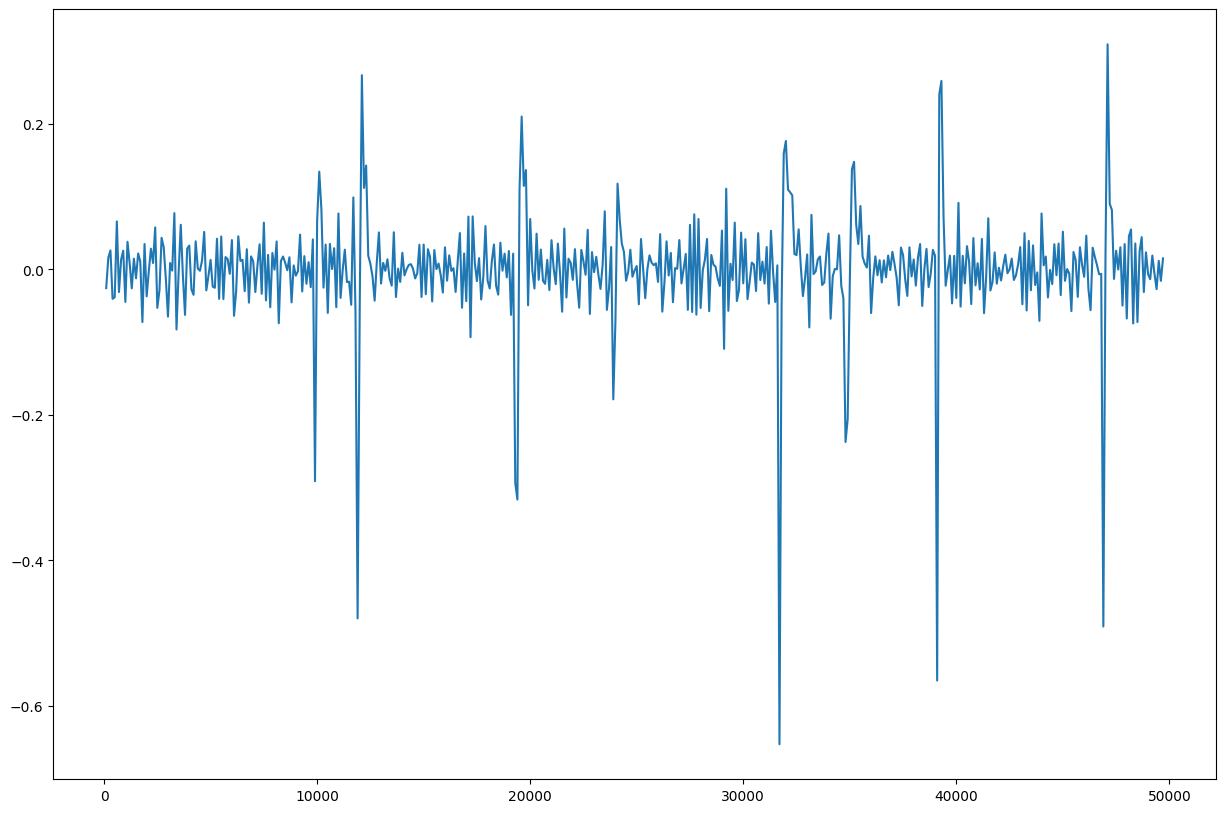

In [ ]:
dati_min=data[3]
mins=[]
for i in range(1, len(dati_min['time']) - 1):
    # Verifica l'attraversamento dello zero da negativo a positivo (punto di minimo)
    if dati_min['der_1'].iloc[i+1] > 0 and dati_min['der_1'].iloc[i-1] < 0:
        if dati_min['der_1'][i] < 0:
            mins.append(int((2 * i + 1) / 2))
        elif dati_min['der_1'][i] > 0:
            mins.append(int((2 * i - 1) / 2))

plt.figure(figsize=(15, 10))
plt.plot(dati_min['time'], dati_min['der_1'], label='canale 1')
#plt.plot(df_der['time'], df_der['der_2'], label='canale 2')
# Estrae i tempi corrispondenti agli indici e plotta i punti sulla curva della derivata
plt.scatter(df['time'].iloc[mins*100], df['signal1'].iloc[mins*100], marker="*", color='red', s=150, label='minimi')
plt.xlabel('tempo [s]')
plt.ylabel('derivata segnale [V/s]')
plt.title(f"derivata oscilloscopio e minimi", fontsize=20)
plt.legend()
#plt.savefig(f"ocsilloscopio_n{step}.png")
plt.show()
'''
mins=[]
for i in range(1, len(dati_min['time']) - 1):
    # Verifica l'attraversamento dello zero da negativo a positivo (punto di minimo)
    if dati_min['der_2'].iloc[i+1] > 0 and dati_min['der_2'].iloc[i-1] < 0:
        if dati_min['der_2'][i] < 0:
            mins.append(int((2 * i + 1) / 2))
        elif dati_min['der_2'][i] > 0:
            mins.append(int((2 * i - 1) / 2))

plt.figure(figsize=(15, 10))
plt.plot(dati_min['time'], dati_min['der_2'], label='canale 1')
plt.plot(df_der['time'], df_der['der_2'], label='canale 2')
# Estrae i tempi corrispondenti agli indici e plotta i punti sulla curva della derivata
plt.scatter(dati_min['time'].iloc[mins], dati_min['der_1'].iloc[mins], marker="*", color='red', s=150, label='minimi')
plt.xlabel('tempo [s]')
plt.ylabel('derivata segnale [V/s]')
plt.title(f"derivata oscilloscopio e minimi", fontsize=20)
plt.legend()
#plt.savefig(f"ocsilloscopio_n{step}.png")
plt.show()'''


        

In [18]:
import numpy as np
# 1. Calcolo derivata con differenza centrale (punto 3)
df['der_1'] = np.gradient(df['signal1'], df['time'])

# 2. Trova dove la derivata passa da negativa (< 0) a positiva (>= 0)
# shift(1) sposta i dati in avanti di 1 posizione per confrontare l'elemento i-1 con l'elemento i
condizione_minimo = (df['der_1'].shift(1) < 0) & (df['der_1'] >= 0)

# Filtra il DataFrame per ottenere direttamente tempi e valori dei minimi
minimi_df = df[condizione_minimo]

print("Posizione (tempo) e valore dei minimi:")
print(minimi_df[['time', 'signal1']])


Posizione (tempo) e valore dei minimi:
        time  signal1
4          4     0.35
7          7    -0.17
14        14    -0.79
19        19    -2.51
21        21    -4.54
...      ...      ...
49895  49895    -0.04
49898  49898     1.20
49901  49901    -1.16
49907  49907     0.91
49910  49910    -1.05

[12529 rows x 2 columns]


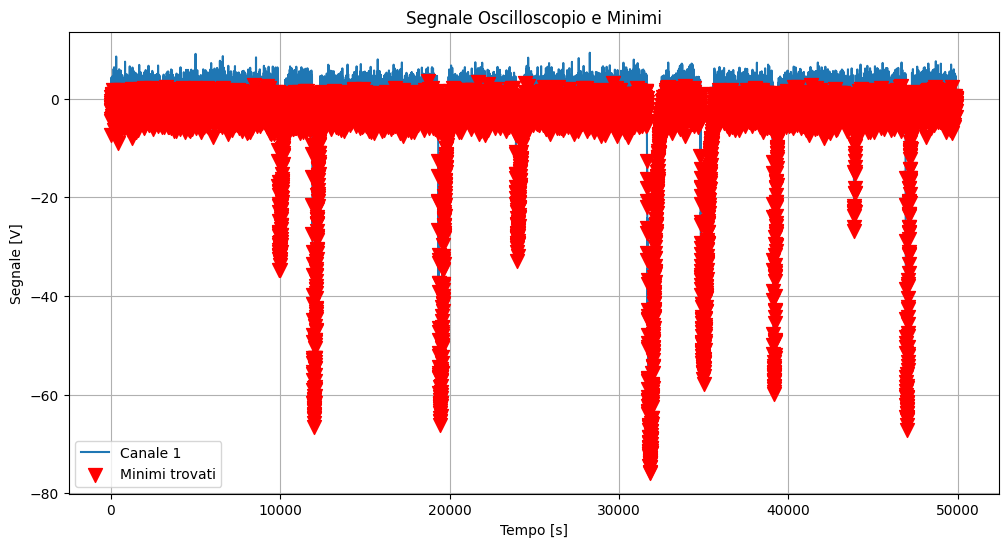

In [19]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.signal import find_peaks

# Trova gli indici dei minimi invertendo il segnale
# Regola 'prominence' (es. 0.5) in base all'ampiezza in Volt del tuo segnale per filtrare il rumore
indici_minimi, _ = find_peaks(-df['signal1'], prominence=0.5)

# Estrai tempo (posizione) e tensione (valore) dei minimi
tempi_minimi = df['time'].iloc[indici_minimi]
valori_minimi = df['signal1'].iloc[indici_minimi]

# Grafico del segnale originale con i minimi evidenziati
plt.figure(figsize=(12, 6))
plt.plot(df['time'], df['signal1'], label='Canale 1')
plt.scatter(tempi_minimi, valori_minimi, color='red', marker='v', s=100, zorder=5, label='Minimi trovati')
plt.xlabel('Tempo [s]')
plt.ylabel('Segnale [V]')
plt.title('Segnale Oscilloscopio e Minimi')
plt.legend()
plt.grid(True)
plt.show()
